# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from matplotlib.colors import ListedColormap, Normalize
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box
import numpy as np
import pandas as pd
import hotspot
import gseapy

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
sdata=sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_factor.zarr")

In [168]:
saving_path='/media/sergio/Meninges/troutpy/figures/msbrain/protrusion_exploration'
os.makedirs(saving_path,exist_ok=True)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,color_key='overlaps_cell',colormap='winter',boundary_linewidth=0.9,scatter_size=0.055,figsize=(30,30))
plt.savefig(os.path.join(saving_path,'overlaps_cell_example_2_winter.png'),dpi=900)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,color_key='overlaps_cell',colormap='pink',boundary_linewidth=0.3,scatter_size=0.05,figsize=(15,15),use_roi=True,roi=[4000,5000,1500,2500])
plt.savefig(os.path.join(saving_path,'overlaps_cell_example_2_pink_roi.png'),dpi=500)

No transformation matrix found. Proceeding without transformation.


In [32]:
transcripts=sdata['transcripts'][['x','y','gene','extracellular','closest_cell_type','cosine_similarity','overlaps_cell']].compute()
dict_anno={0:'DG',1:'Oligodendrocytes',2:'CA1-2',3:'Astrocytes',4:'Endothelial',5:'EXC neurons Thal.',6:'CA3',7:'EXC. neurons CTX',8:'SMC/Pericytes',
9:'Microglia',10:'Ependymal cells',11:'INH neurons',12:'OPC',13:'Astrocytes',14:'SGZ Neuroblasts',15:'Oligodendrocytes',16:'Cajal-Retzius',17:'Choroid plexus',
18:'Astrocytes',19:'INH neurons CP'}
transcripts['cell_type']=transcripts['closest_cell_type'].astype(int).map(dict_anno)


In [31]:
sdata['transcripts']

,x,y,z,gene,cell_id,is_gene,overlaps_nucleus,transcript_id,nucleus_distance,codeword_category,qv,fov_name,codeword_index,control_probe,overlaps_cell,xy,closest_cell_type,cosine_similarity,assignment_score,match_cell_signature,extracellular
npartitions=8,,,,,,,,,,,,,,,,,,,,,
,float32,float32,float32,category[unknown],string,bool,bool,string,float32,string,float32,string,int32,bool,bool,string,string,float64,float64,bool,bool
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


In [56]:
import matplotlib.pyplot as plt

def plot_celltype_spatial(transcripts, cell_type, score_col='cosine_similarity', x_col='x', y_col='y', cmap='viridis', s=0.005):
    """
    Plot spatial map of spots for a specific cell type.
    Extracellular spots are plotted in red, others colored by score_col.
    """
    df = transcripts[transcripts['cell_type'] == cell_type]
    
    # Split extracellular vs non-extracellular
    df_ex = df[df['extracellular'] == True]
    df_in = df[df['extracellular'] == False]

    df_cell = df_in[df_in['overlaps_cell'] == True]
    df_in = df_in[df_in['overlaps_cell'] == False]
    
    plt.figure(figsize=(15, 12))
    
    
    # Extracellular: red
    plt.scatter(df_ex[x_col], df_ex[y_col], color='#b1a5b5', s=0.00001, label='Extracellular')

     # Extracellular: red
    plt.scatter(df_cell[x_col], df_cell[y_col], color='black', s=0.000006, label='Cellular')

    # Non-extracellular: colored by cosine_similarity
    sc=plt.scatter(df_in[x_col], df_in[y_col], c=df_in[score_col], cmap=cmap, s=s, label='Non-extracellular')
    
    plt.colorbar(sc, label=score_col)
    plt.title(f"Spatial map of {cell_type}")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.gca().invert_yaxis()
    plt.legend()


In [ ]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

cell_types = transcripts['cell_type'].unique()

for ct in cell_types[:14]:
    plot_celltype_spatial(transcripts, ct,cmap='rainbow',s=0.00001)
    plt.savefig(os.path.join(saving_path,'map_of_cell_like_'+ct.replace('/','')+'.png'))
    plt.show()

# Transcripts

In [57]:
trans_seg=transcripts[transcripts['extracellular']==False]
segmented_prop=pd.crosstab(trans_seg['cell_type'],trans_seg['overlaps_cell'])
segmented_prop=segmented_prop.div(segmented_prop.sum(axis=1),axis=0)
segmented_prop=segmented_prop.sort_values(by=False)
dict_col=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))

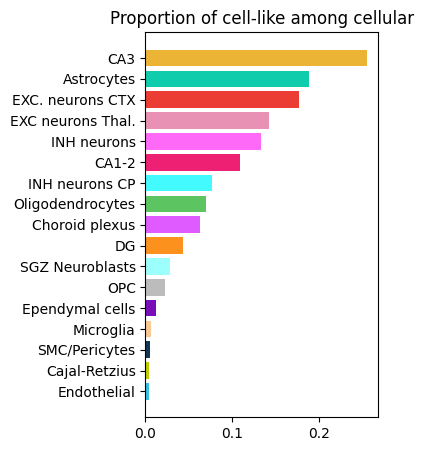

In [176]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

plt.figure(figsize=(3,5))

# Map cell types (index) to colors from your dict
bar_colors = [dict_col.get(ct, "gray") for ct in segmented_prop.index]

plt.barh(segmented_prop.index,segmented_prop[False],color=bar_colors)

plt.title("Proportion of cell-like among cellular")
plt.savefig(os.path.join(saving_path,'proportion_of_cell_like_among_cellular.pdf'))
plt.show()


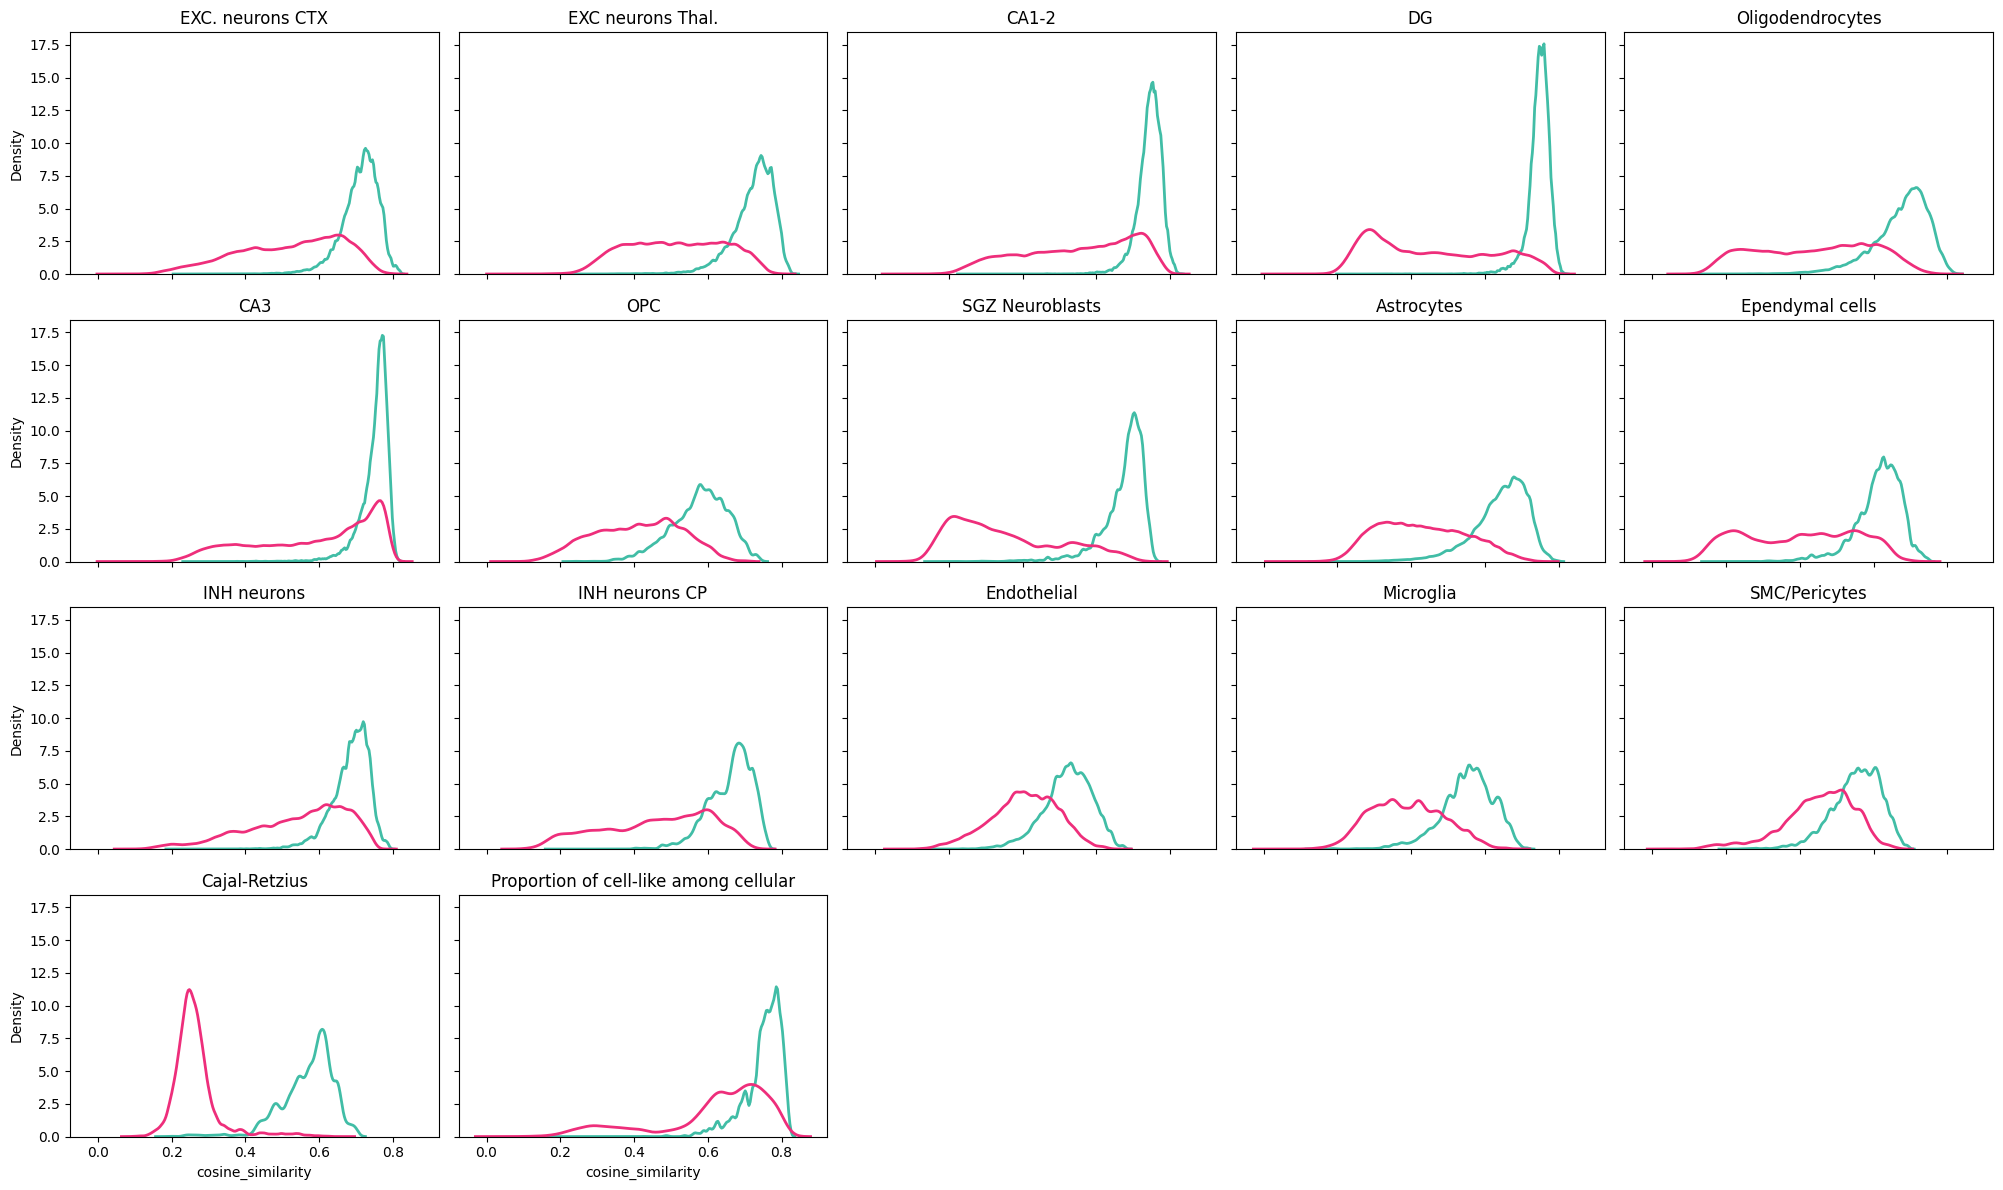

In [177]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

def plot_cosine_similarity_kde_by_celltype(transcripts, score_col='cosine_similarity'):
    """
    Plot KDE distribution of cosine similarity for each cell type,
    separating extracellular vs cellular, all cell types in a single figure.
    """
    cell_types = transcripts['cell_type'].unique()
    n_celltypes = len(cell_types)
    n_cols = 5  # adjust number of columns
    n_rows = math.ceil(n_celltypes / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*3), sharex=True, sharey=True)
    axes = axes.flatten()

    for i, ct in enumerate(cell_types):
        ax = axes[i]
        df_ct = transcripts[transcripts['cell_type'] == ct]
        
        sns.kdeplot(
            data=df_ct[df_ct['overlaps_cell'] == True],
            x=score_col,
            label='Cellular',
            color='#41bda6',
            fill=False,
            linewidth=2,
            ax=ax
        )
        sns.kdeplot(
            data=df_ct[df_ct['overlaps_cell'] == False],
            x=score_col,
            label='Extracellular',
            color='#ee2e7b',
            fill=False,
            linewidth=2,
            ax=ax
        )
        ax.set_title(ct)
        ax.set_xlabel(score_col)
        ax.set_ylabel("Density")
#        ax.legend()

    # Remove empty subplots if any
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plot_cosine_similarity_kde_by_celltype(transcripts)

plt.title("Proportion of cell-like among cellular")
plt.savefig(os.path.join(saving_path,'cosine_similarity_density_by_cell_type.pdf'))


In [85]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

# extracellular transcripts (outside cells)
extracell = trans_seg[trans_seg['overlaps_cell']==False].copy()

# intracellular transcripts (inside cells)
intracell = trans_seg[trans_seg['overlaps_cell']==True].copy()

# coordinates
X_extra = extracell[['x','y']].values
X_intra = intracell[['x','y']].values

# fit nearest neighbor model
nbrs = NearestNeighbors(n_neighbors=1, algorithm='kd_tree').fit(X_intra)

# find nearest neighbor distances
distances, indices = nbrs.kneighbors(X_extra)

# add distances as new column
extracell['dist_to_nearest_cell'] = distances[:,0]

# Optional: merge back to original dataframe
# Option 2: merge on index
trans_seg = trans_seg.merge(
    extracell[['dist_to_nearest_cell']],
    left_index=True,
    right_index=True,  # must be True
    how='left')


ValueError: right_index parameter must be of type bool, not <class 'pandas.core.indexes.base.Index'>

In [94]:
trans_miss=trans_seg[trans_seg['overlaps_cell']==False]

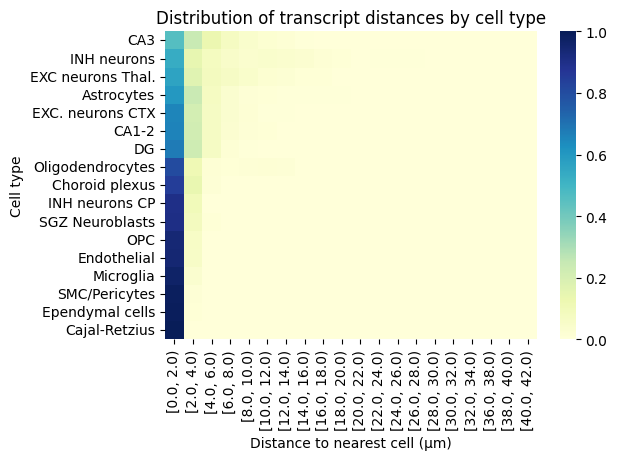

In [181]:
import numpy as np

# define bin edges (adjust max value as needed)
bin_edges = np.arange(0, trans_miss['dist_to_nearest_cell'].max() + 2, 2)

# create interval bins
trans_miss['dist_bin'] = pd.cut(trans_miss['dist_to_nearest_cell'], bins=bin_edges, right=False)

# compute frequencies
freqs = pd.crosstab(trans_miss['cell_type'], trans_miss['dist_bin'])
freqs = freqs.div(freqs.sum(axis=1), axis=0)

# optional: sort by first bin instead of 0.0
first_bin = freqs.columns[0]
freqs = freqs.sort_values(by=first_bin)

# plot
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

plt.figure(figsize=(6,4))
sns.heatmap(freqs, cmap='YlGnBu')
plt.xlabel("Distance to nearest cell (µm)")
plt.ylabel("Cell type")
plt.title("Distribution of transcript distances by cell type")
plt.savefig(os.path.join(saving_path, 'heatmap_distance_cell_like_by_celltype.pdf'))


# Proportion of distant cell-like

In [140]:
trans_miss['close_10']=trans_miss['dist_to_nearest_cell']<10
close_urna=pd.crosstab(trans_miss['cell_type'],trans_miss['close_10'])
close_urna=close_urna.div(close_urna.sum(axis=1),axis=0)
close_urna=close_urna.sort_values(by=False)

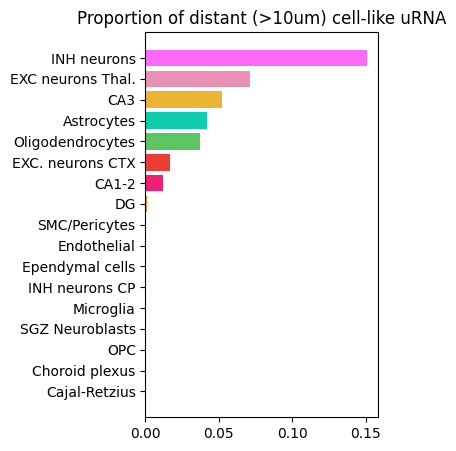

In [182]:
plt.figure(figsize=(3,5))

# Map cell types (index) to colors from your dict
bar_colors = close_urna.index.map(dict_col)

plt.barh(
    close_urna.index,
    close_urna[False],
    color=bar_colors
)

plt.title('Proportion of distant (>10um) cell-like uRNA')
plt.savefig(os.path.join(saving_path,'proportion_of_distantcell_like.pdf'))
plt.show()


### Contiue with distance by gene

In [184]:
trans_seg[

,x,y,gene,extracellular,closest_cell_type,cosine_similarity,overlaps_cell,cell_type,dist_to_nearest_cell
2,5439.609375,1217.343750,Csde1,False,2,0.709791,True,CA1-2,NaN
3,5008.171875,2574.484375,Snrpn,False,2,0.768471,True,CA1-2,NaN
4,4995.265625,1523.281250,Runx2,False,0,0.724412,True,DG,NaN
5,4070.093750,1289.375000,Dnm1,False,5,0.679840,True,EXC neurons Thal.,NaN
6,4292.156250,2855.156250,Ppp1r7,False,1,0.702830,True,Oligodendrocytes,NaN
...,...,...,...,...,...,...,...,...,...
23879019,5006.640625,2559.296875,Snrpn,False,2,0.730399,False,CA1-2,1.908554
23879020,4559.328125,1919.375000,Cdc42bpb,False,6,0.788845,True,CA3,NaN
23879021,4279.421875,2879.562500,Ppp1r7,False,10,0.662637,True,Ependymal cells,NaN
23879022,4994.046875,1602.250000,Runx2,False,0,0.766498,True,DG,NaN


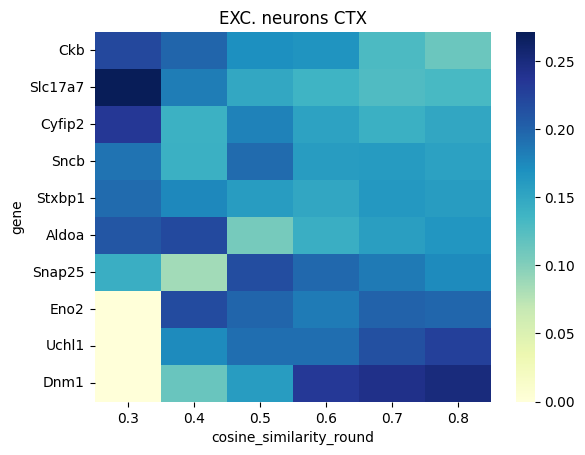

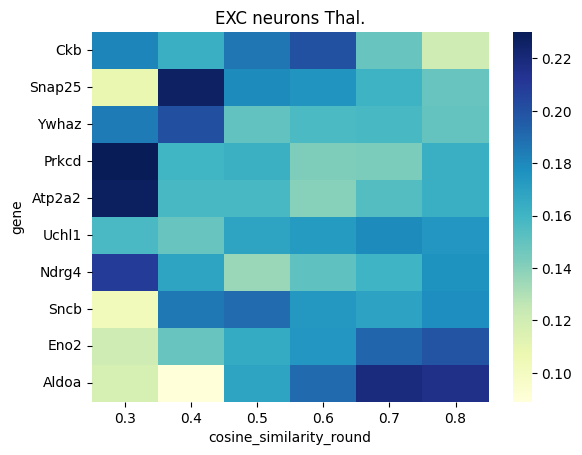

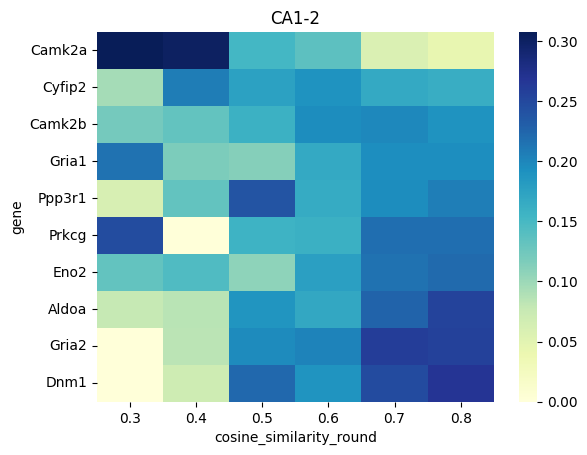

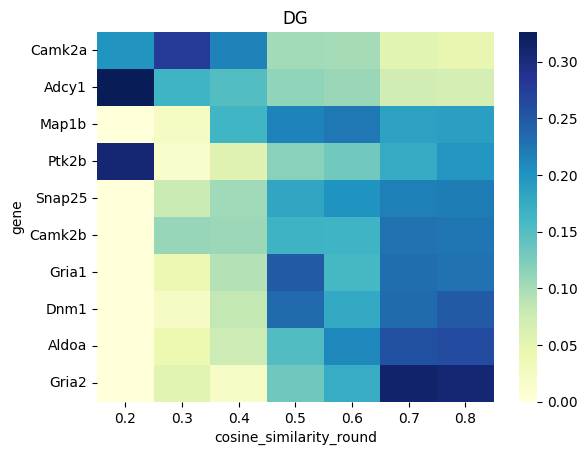

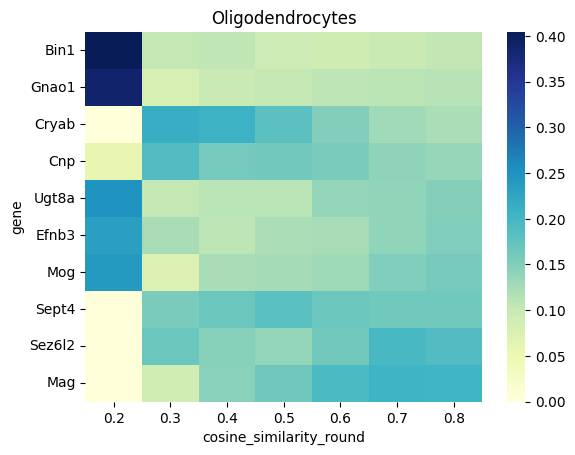

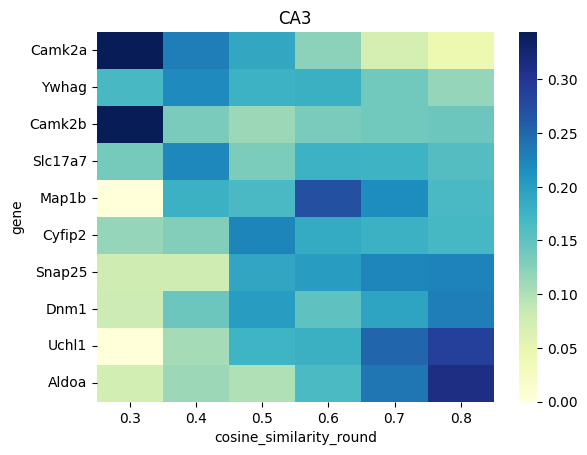

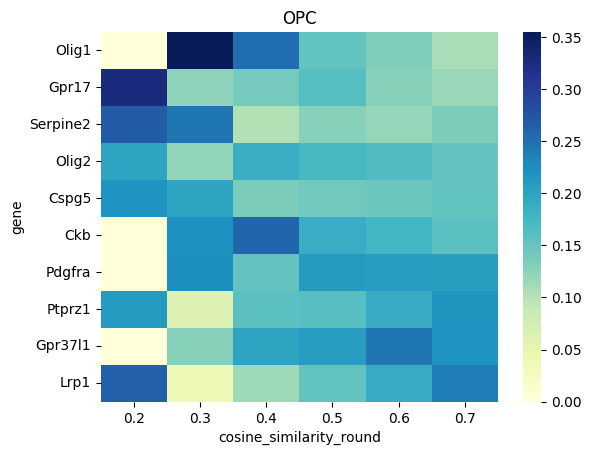

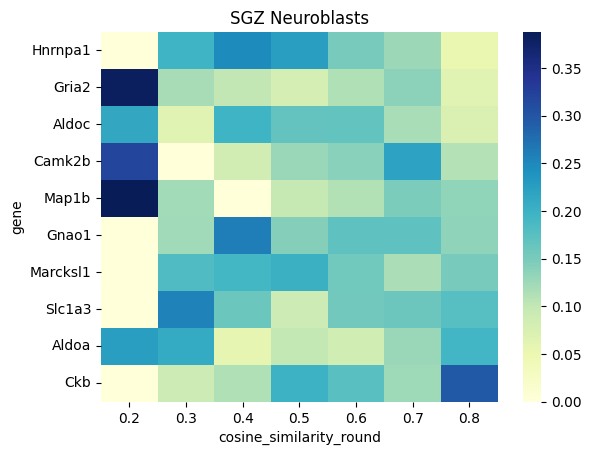

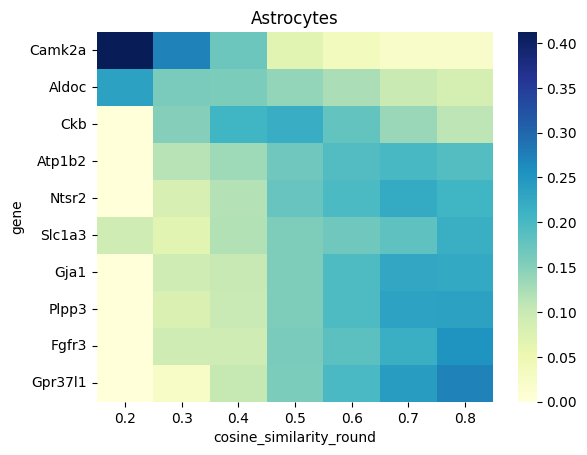

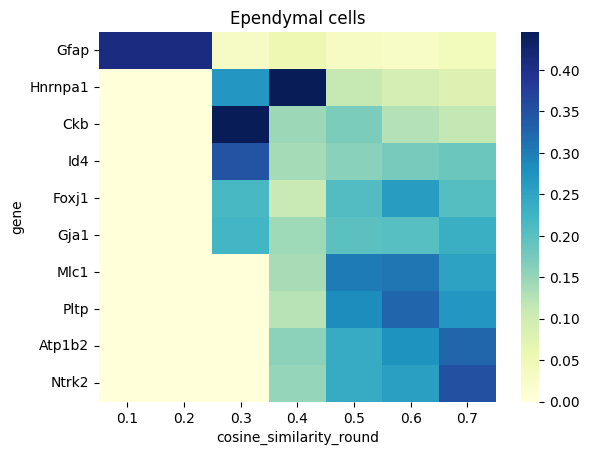

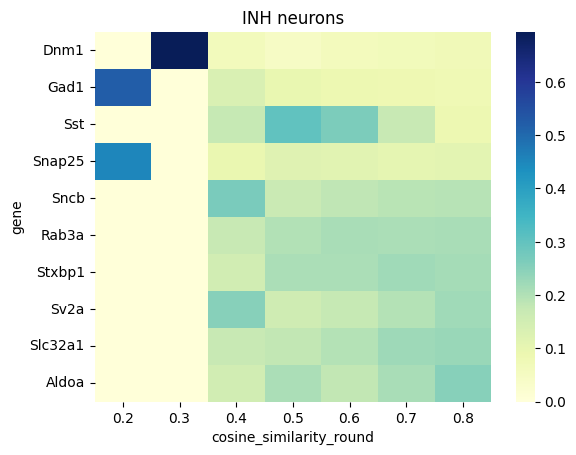

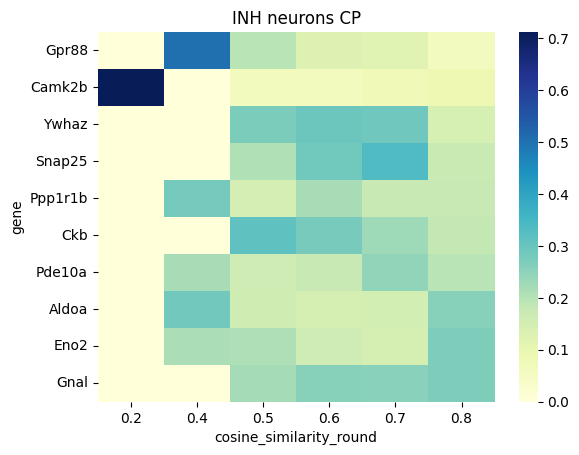

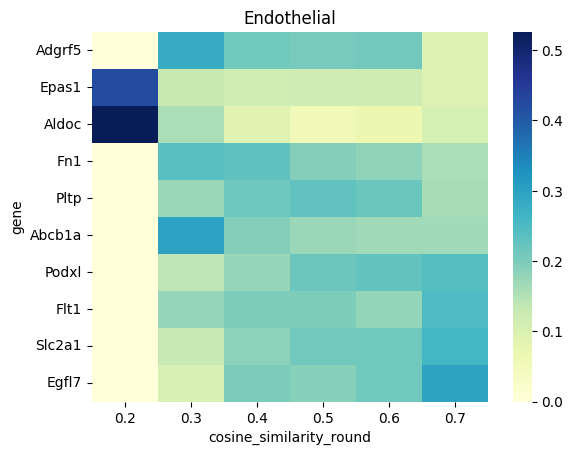

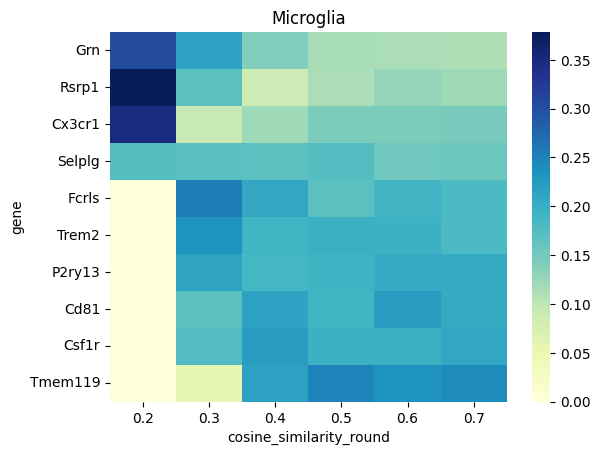

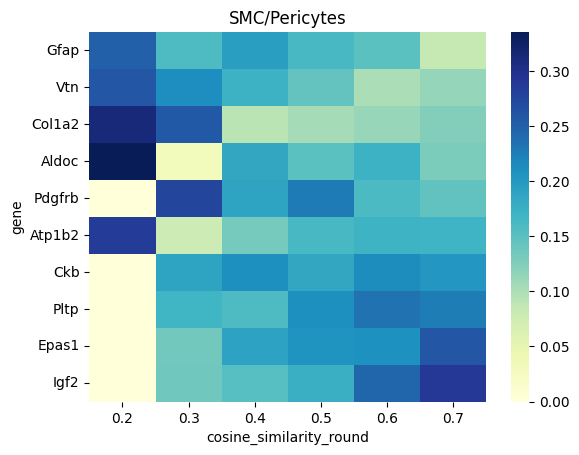

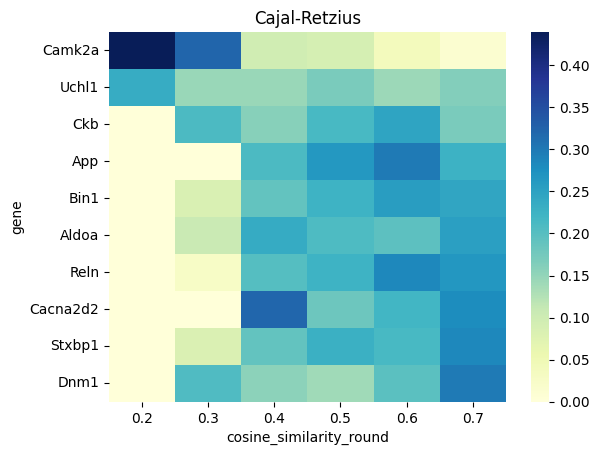

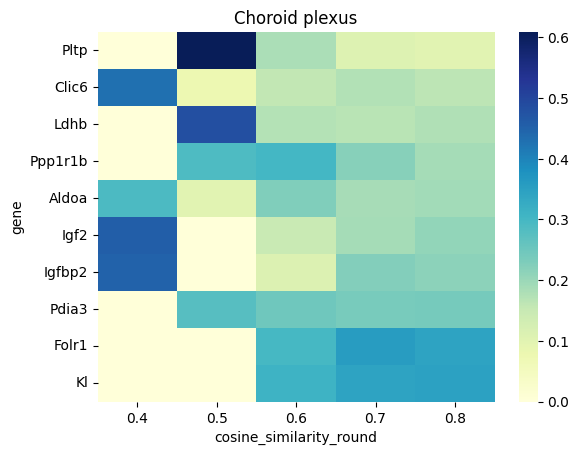

In [242]:
for c in cell_types:
    tr_sub=trans_seg[trans_seg['cell_type']==c]
    genes_sel=tr_sub.groupby('gene').count().sort_values(by='x',ascending=False).index[0:10]
    tr_s=tr_sub[tr_sub['gene'].isin(genes_sel)]
    tr_s['cosine_similarity_round']=tr_s['cosine_similarity'].round(1)
    cosim=pd.crosstab(tr_s['cosine_similarity_round'],tr_s['gene'])
    cosim=cosim.div(cosim.sum(axis=1),axis=0)
    cosim=cosim.div(cosim.sum(axis=0),axis=1)
    cosim=cosim.transpose().sort_values(by=cosim.index[-1])
    sns.heatmap(cosim,cmap='YlGnBu')
    plt.title(c)
    plt.show()
    